This map shows wind by ccaa

Años disponibles: 21
Territorios disponibles: 19

Media de viento:
                     comunidad  media_viento
7              Ciudad de Ceuta     27.206667
2                     Canarias     25.976667
14               Illes Balears     18.904762
13                     Galicia     18.431905
8            Ciudad de Melilla     17.172381
1                       Aragón     17.101905
9   Comunidad Foral de Navarra     17.056667
5           Castilla-La Mancha     17.035714
4              Castilla y León     16.557143
12                 Extremadura     15.635714
16                  País Vasco     15.475238
11        Comunitat Valenciana     14.898571
15                    La Rioja     14.524286
0                    Andalucía     14.285714
10         Comunidad de Madrid     14.166190
17      Principado de Asturias     13.883810
18            Región de Murcia     13.269524
3                    Cantabria     12.933810
6                     Cataluña     12.530000


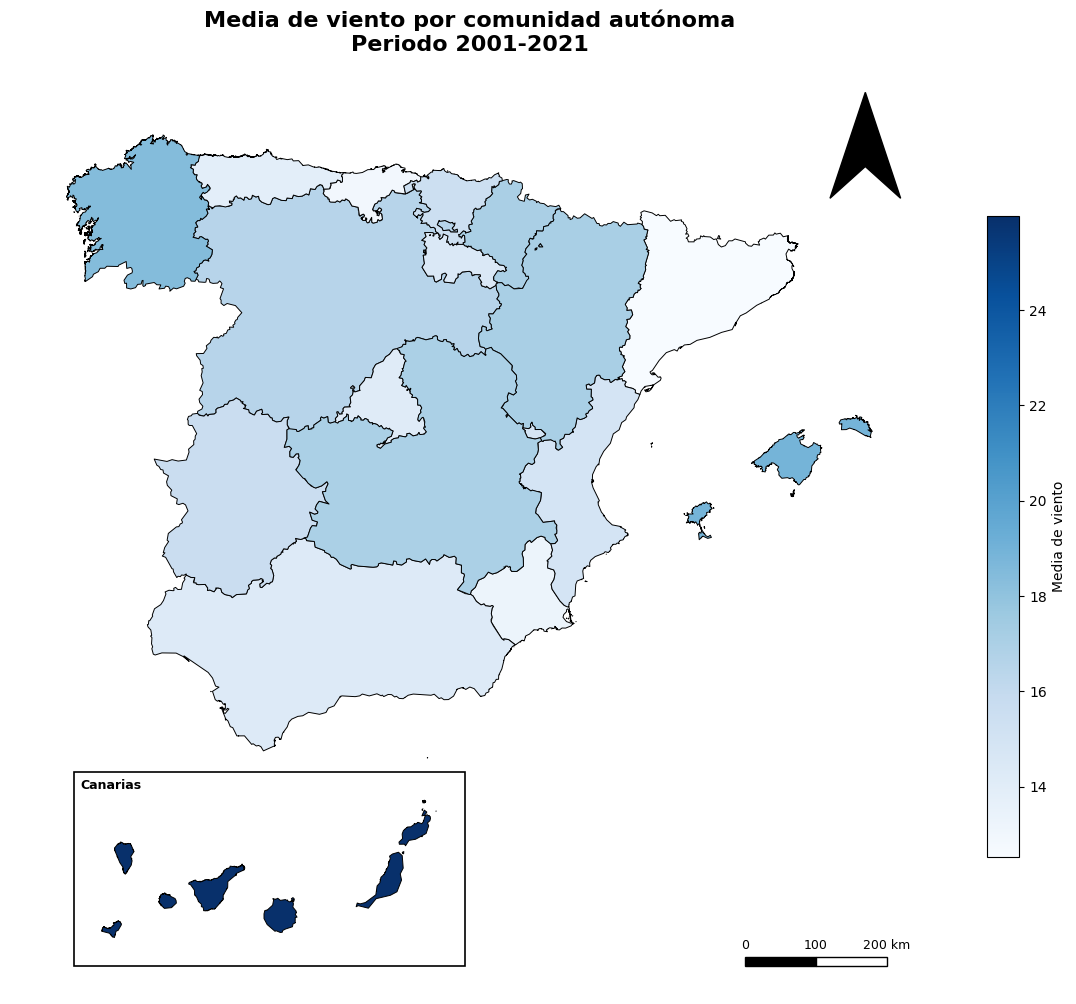


Análisis finalizado correctamente.


In [34]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Polygon
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["wind_speed_100m_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_viento"
]

print("\nMedia de viento:")
print(media_precipitacion.sort_values(
    "media_viento",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_viento"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_viento"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_viento",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de viento",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# Límites para que quepa todo (recuadro de Canarias incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (200 km) ----
tramo = 100_000
alto = 12_000
sb_x0 = xmax - 2 * tramo - 60_000
sb_y0 = ymin + 40_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 150_000      # altura de la flecha (m)
ancho_flecha = 100_000     # anchura de la flecha (m)
fx = xmax - 90_000         # centro horizontal
fy = ymax - 20_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media de viento por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_viento_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_viento_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

This first code makes a map of CCAA , rain sum. The arrow indicates the orientation of the map

Años disponibles: 21
Territorios disponibles: 19

Media de litros acumulados:
                     comunidad  media_litros_acumulados
17      Principado de Asturias              1179.709048
13                     Galicia              1174.668571
3                    Cantabria              1071.800952
16                  País Vasco               990.978095
9   Comunidad Foral de Navarra               775.434286
6                     Cataluña               682.228571
15                    La Rioja               638.989048
7              Ciudad de Ceuta               588.395238
4              Castilla y León               557.947619
12                 Extremadura               547.543810
1                       Aragón               508.673810
0                    Andalucía               490.892857
11        Comunitat Valenciana               469.583810
10         Comunidad de Madrid               459.258095
5           Castilla-La Mancha               454.348571
14               Illes Bal

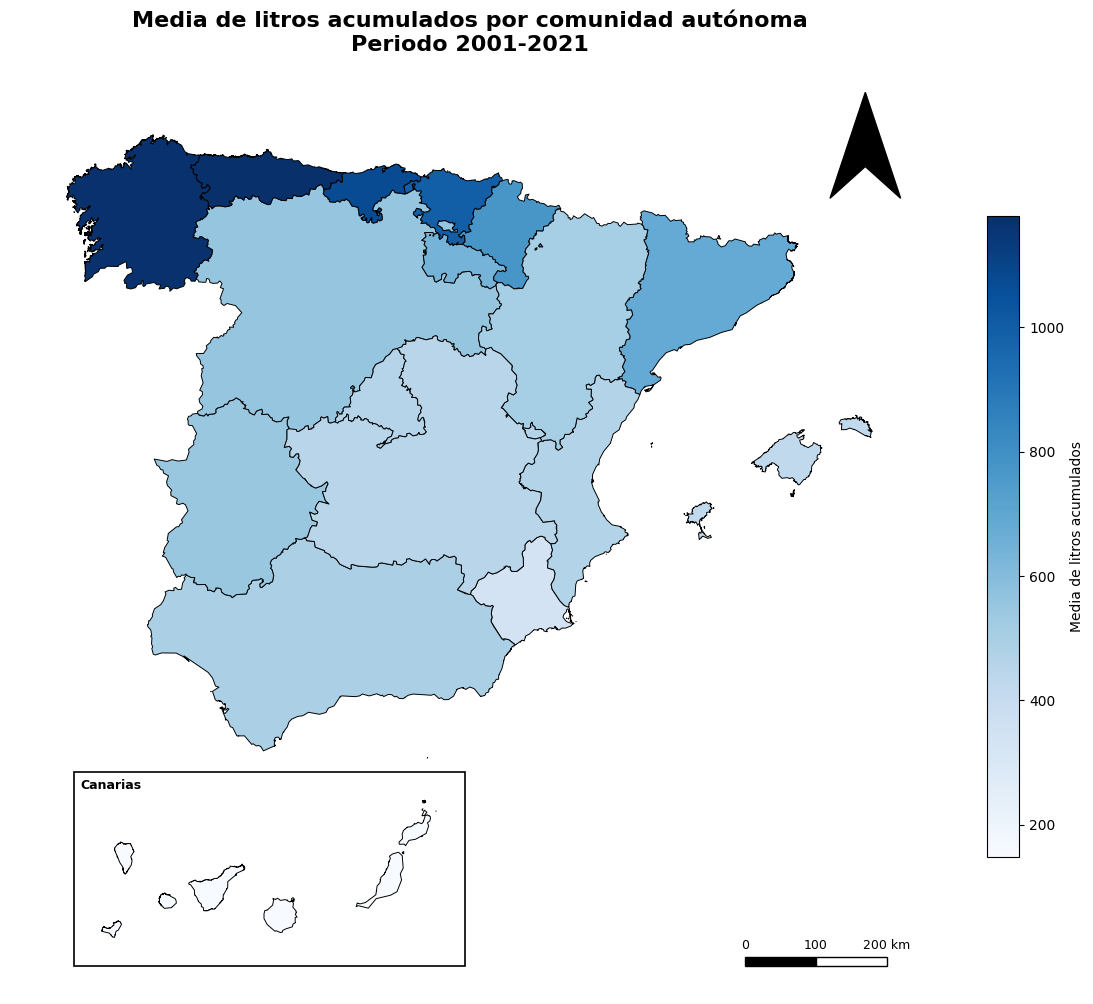


Análisis finalizado correctamente.


In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Polygon
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["rain_sum"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_litros_acumulados"
]

print("\nMedia de litros acumulados:")
print(media_precipitacion.sort_values(
    "media_litros_acumulados",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_litros_acumulados"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_litros_acumulados"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_litros_acumulados",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de litros acumulados",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# Límites para que quepa todo (recuadro de Canarias incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (200 km) ----
tramo = 100_000
alto = 12_000
sb_x0 = xmax - 2 * tramo - 60_000
sb_y0 = ymin + 40_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 150_000      # altura de la flecha (m)
ancho_flecha = 100_000     # anchura de la flecha (m)
fx = xmax - 90_000         # centro horizontal
fy = ymax - 20_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media de litros acumulados por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_precipitaciones_acumuladas_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_precipitaciones_acumuladas_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

This map shows cloud cover time per CCAA

Años disponibles: 21
Territorios disponibles: 19

Media de nubosidad:
                     comunidad  media_nubosidad
17      Principado de Asturias        66.746667
3                    Cantabria        65.894286
16                  País Vasco        65.030952
13                     Galicia        61.159048
9   Comunidad Foral de Navarra        59.028095
15                    La Rioja        57.551905
4              Castilla y León        52.746667
6                     Cataluña        49.062381
1                       Aragón        46.164762
10         Comunidad de Madrid        45.005238
5           Castilla-La Mancha        43.687619
11        Comunitat Valenciana        42.624286
12                 Extremadura        41.051905
14               Illes Balears        40.826190
8            Ciudad de Melilla        39.927143
2                     Canarias        39.575238
18            Región de Murcia        39.365714
0                    Andalucía        38.850476
7              Ciu

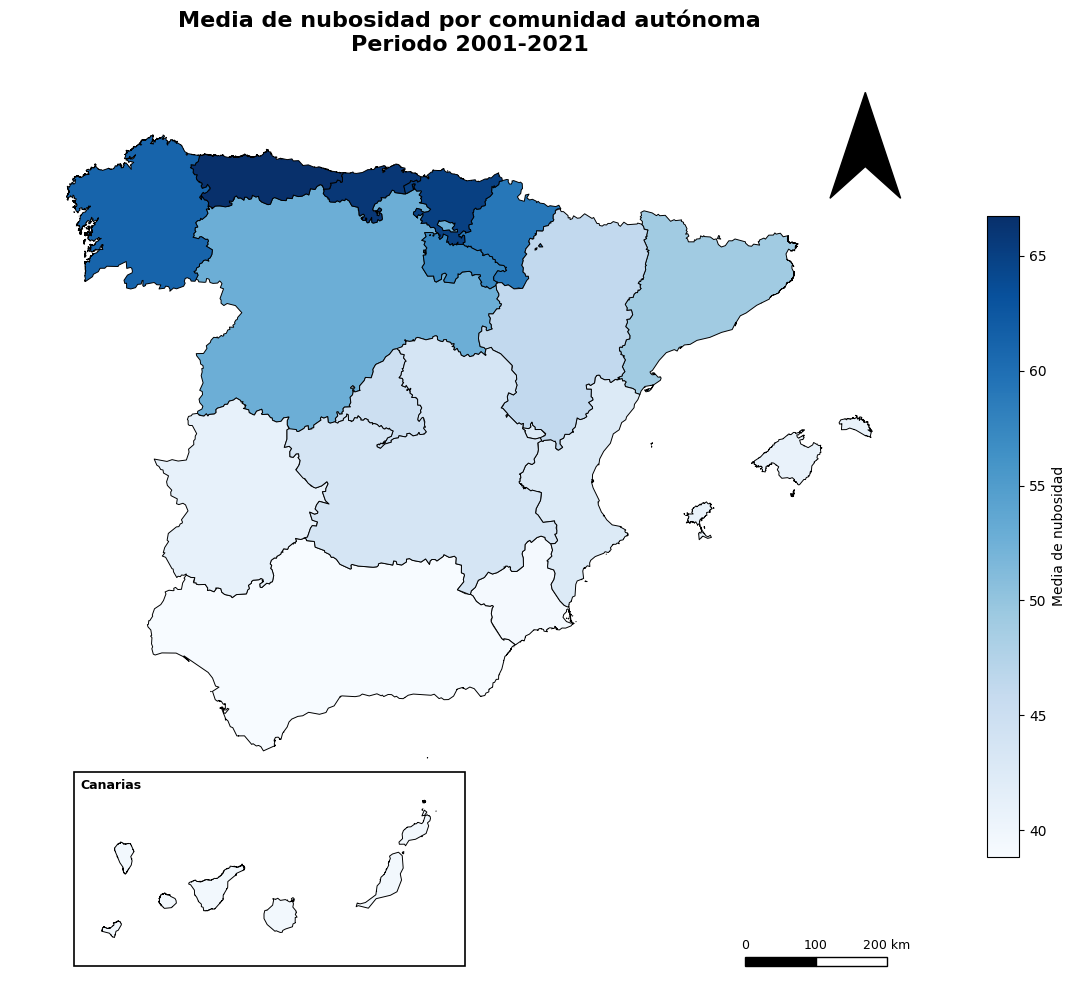


Análisis finalizado correctamente.


In [4]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Polygon
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["cloud_cover_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_nubosidad"
]

print("\nMedia de nubosidad:")
print(media_precipitacion.sort_values(
    "media_nubosidad",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_nubosidad"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_nubosidad"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_nubosidad",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de nubosidad",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# Límites para que quepa todo (recuadro de Canarias incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (200 km) ----
tramo = 100_000
alto = 12_000
sb_x0 = xmax - 2 * tramo - 60_000
sb_y0 = ymin + 40_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 150_000      # altura de la flecha (m)
ancho_flecha = 100_000     # anchura de la flecha (m)
fx = xmax - 90_000         # centro horizontal
fy = ymax - 20_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media de nubosidad por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_nubosidad_espana_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_nubosidad_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

This code makes a map of CCAA , precipitation hours.

Años disponibles: 21
Territorios disponibles: 19

Media de horas de precipitación:
                     comunidad  media_horas_precipitacion
17      Principado de Asturias                2193.840476
3                    Cantabria                2158.795714
16                  País Vasco                1931.740000
13                     Galicia                1842.459048
9   Comunidad Foral de Navarra                1444.766667
15                    La Rioja                1404.707619
4              Castilla y León                1151.822381
6                     Cataluña                1095.566667
1                       Aragón                 917.027143
10         Comunidad de Madrid                 911.108095
7              Ciudad de Ceuta                 907.761905
5           Castilla-La Mancha                 854.774286
12                 Extremadura                 836.772381
0                    Andalucía                 773.963333
11        Comunitat Valenciana                 

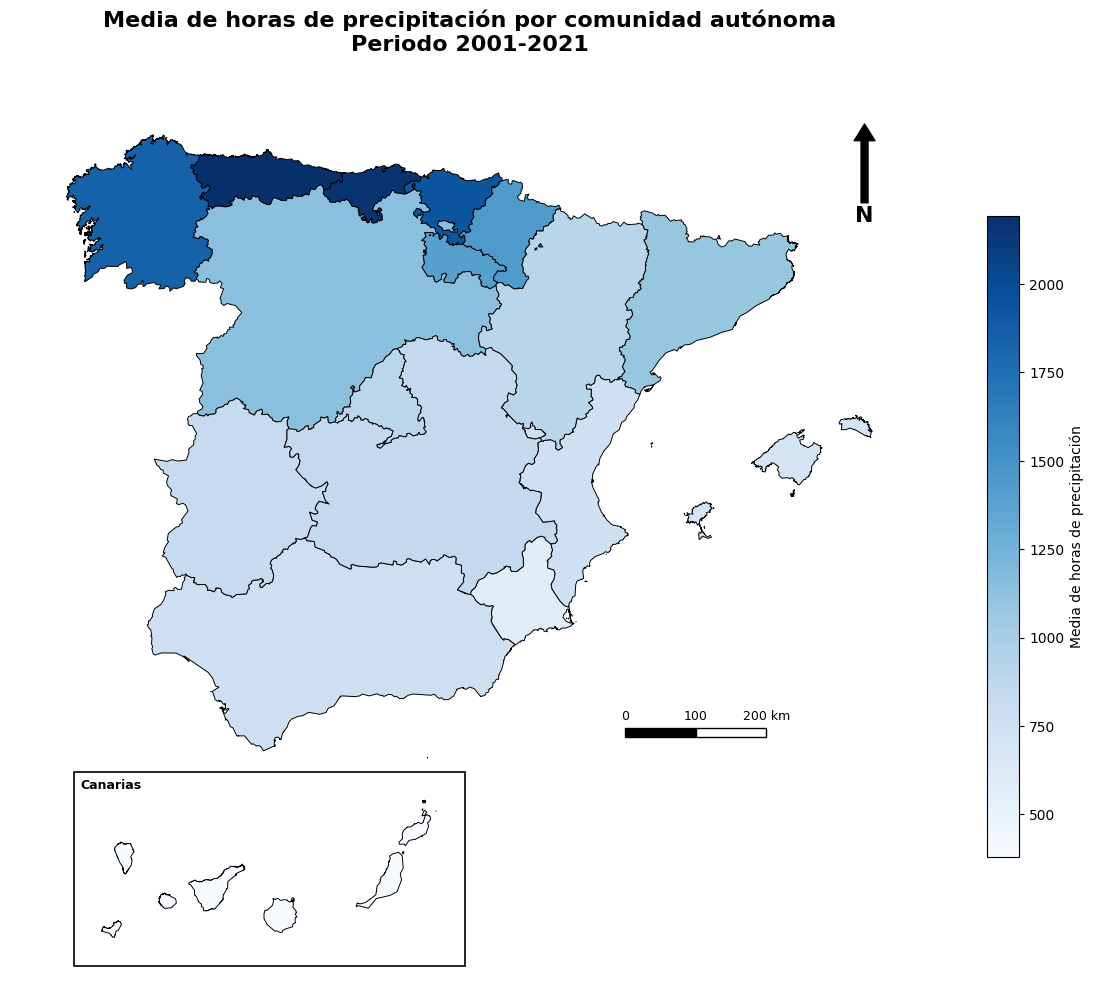


Análisis finalizado correctamente.


In [5]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["precipitation_hours"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_horas_precipitacion"
]

print("\nMedia de horas de precipitación:")
print(media_precipitacion.sort_values(
    "media_horas_precipitacion",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_horas_precipitacion"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_horas_precipitacion"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_horas_precipitacion",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de horas de precipitación",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# ---- Barra de escala (200 km, en tramos de 100 km) ----
sb_x0 = pen_maxx - 350_000
sb_y0 = pen_miny + 30_000
tramo = 100_000
alto = 12_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte ----
ax.annotate(
    "N",
    xy=(0.93, 0.95),
    xytext=(0.93, 0.85),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    arrowprops=dict(facecolor="black", width=5, headwidth=15)
)

# Límites para que quepa todo (recuadro incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

ax.set_title(
    "Media de horas de precipitación por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_precipitaciones_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_precipitaciones_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

This code makes a maps of CCAA, temperature_2m_mean

Años disponibles: 21
Territorios disponibles: 19

Media de temperatura:
                     comunidad  media_temperatura
8            Ciudad de Melilla          19.586190
2                     Canarias          18.797143
14               Illes Balears          18.380952
7              Ciudad de Ceuta          17.762381
0                    Andalucía          16.829524
18            Región de Murcia          16.763810
12                 Extremadura          16.375714
11        Comunitat Valenciana          16.003333
5           Castilla-La Mancha          14.618095
10         Comunidad de Madrid          13.919524
1                       Aragón          13.396667
6                     Cataluña          13.354286
9   Comunidad Foral de Navarra          12.749524
16                  País Vasco          12.725714
13                     Galicia          12.520476
3                    Cantabria          11.912857
4              Castilla y León          11.862381
17      Principado de Asturi

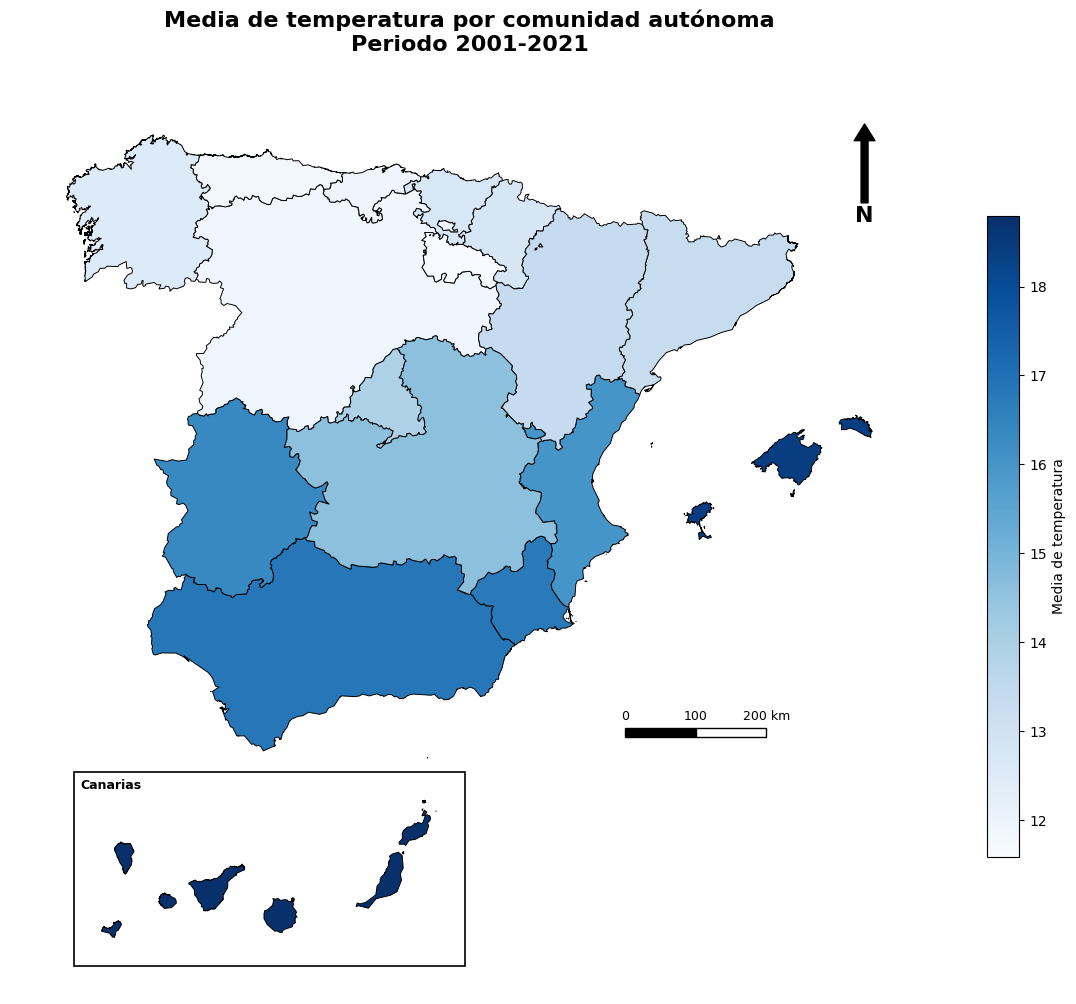


Análisis finalizado correctamente.


In [6]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["temperature_2m_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_temperatura"
]

print("\nMedia de temperatura:")
print(media_precipitacion.sort_values(
    "media_temperatura",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_temperatura"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_temperatura"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_temperatura",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de temperatura",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# ---- Barra de escala (200 km, en tramos de 100 km) ----
sb_x0 = pen_maxx - 350_000
sb_y0 = pen_miny + 30_000
tramo = 100_000
alto = 12_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte ----
ax.annotate(
    "N",
    xy=(0.93, 0.95),
    xytext=(0.93, 0.85),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    arrowprops=dict(facecolor="black", width=5, headwidth=15)
)

# Límites para que quepa todo (recuadro incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

ax.set_title(
    "Media de temperatura por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_temperatura_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_temperatura_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

This code shows a map of CCAA, daylight duration.

Años disponibles: 21
Territorios disponibles: 19

Media de duracion:
                     comunidad  media_duracion
17      Principado de Asturias    43982.832381
3                    Cantabria    43980.116190
16                  País Vasco    43977.562857
13                     Galicia    43972.398095
9   Comunidad Foral de Navarra    43971.006190
15                    La Rioja    43963.959048
6                     Cataluña    43955.693810
4              Castilla y León    43955.343333
1                       Aragón    43950.596667
10         Comunidad de Madrid    43934.569048
5           Castilla-La Mancha    43919.917619
14               Illes Balears    43919.312857
11        Comunitat Valenciana    43917.087143
12                 Extremadura    43913.182857
18            Región de Murcia    43895.828095
0                    Andalucía    43888.466667
7              Ciudad de Ceuta    43868.951429
8            Ciudad de Melilla    43859.356667
2                     Canarias    4378

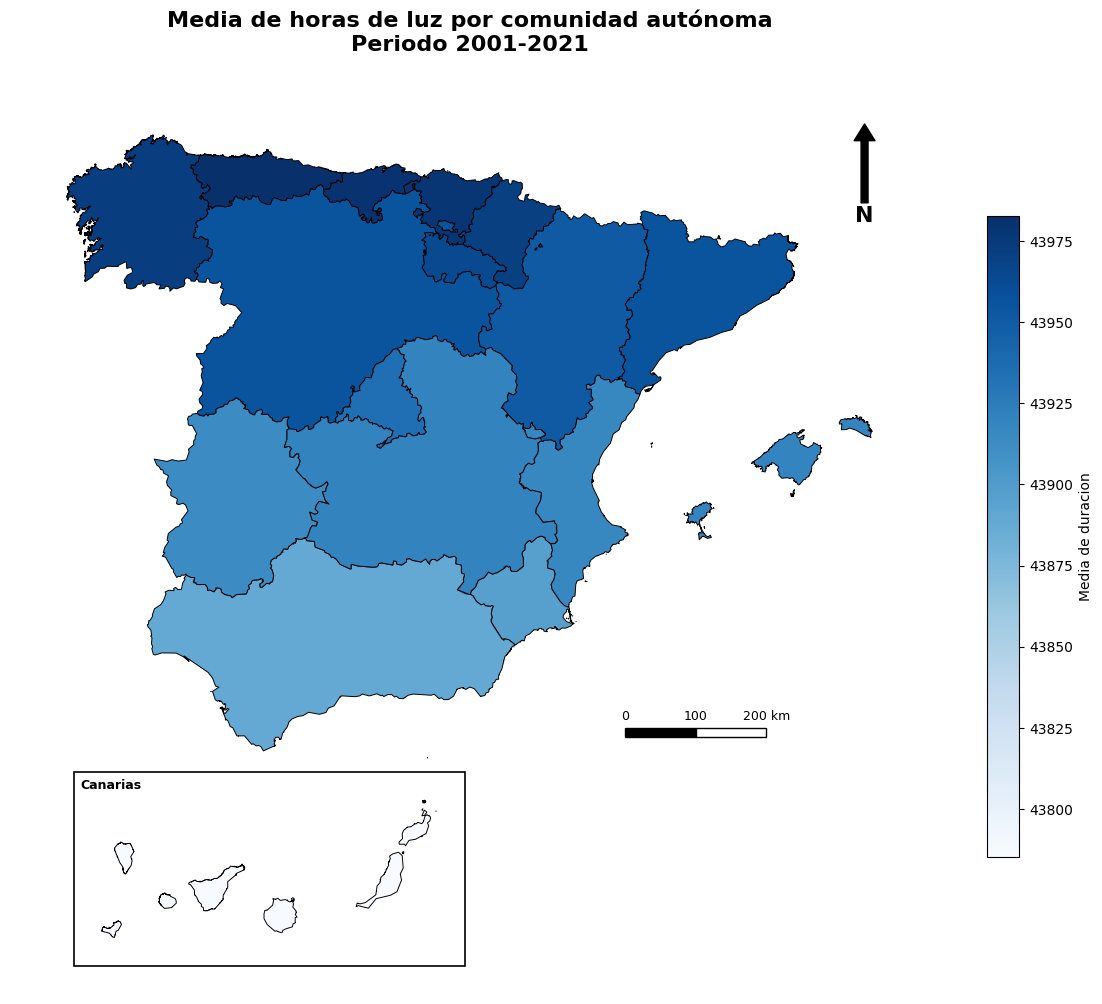


Análisis finalizado correctamente.


In [7]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Territorios disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["daylight_duration"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = [
    "comunidad",
    "media_duracion"
]

print("\nMedia de duracion:")
print(media_precipitacion.sort_values(
    "media_duracion",
    ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)

# --------------------------------------------------
# 4. NORMALIZAR LOS NOMBRES PARA UNIR LOS DATOS
# --------------------------------------------------

def normalizar(nombre):
    nombre = str(nombre).lower().strip()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    return nombre.replace("-", " ").replace("_", " ")

equivalencias = {
    "asturias": "principado de asturias",
    "balearic islands": "illes balears",
    "islas baleares": "illes balears",
    "baleares": "illes balears",
    "canary islands": "canarias",
    "castile and leon": "castilla y leon",
    "castilla leon": "castilla y leon",
    "castilla-leon": "castilla y leon",
    "castilla la mancha": "castilla la mancha",
    "castile la mancha": "castilla la mancha",
    "catalonia": "cataluna",
    "valencian community": "comunitat valenciana",
    "valencia": "comunitat valenciana",
    "basque country": "pais vasco",
    "navarre": "comunidad foral de navarra",
    "navarra": "comunidad foral de navarra",
    "la rioja": "la rioja",
    "madrid": "comunidad de madrid",
    "murcia": "region de murcia",
    "ceuta": "ciudad de ceuta",
    "melilla": "ciudad de melilla"
}

mapa["clave"] = mapa["name"].apply(normalizar)
media_precipitacion["clave"] = (
    media_precipitacion["comunidad"].apply(normalizar)
)

media_precipitacion["clave"] = (
    media_precipitacion["clave"].replace(equivalencias)
)
mapa["clave"] = mapa["clave"].replace(equivalencias)

# --------------------------------------------------
# 4b. QUITAR CEUTA Y MELILLA
# --------------------------------------------------

mapa = mapa[~mapa["clave"].isin(["ciudad de ceuta", "ciudad de melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS DE PRECIPITACIÓN
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion[[
        "clave",
        "media_duracion"
    ]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[
    mapa_final["media_duracion"].isna()
]

if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5b. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros), proyección adecuada para las islas
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

# Posición del recuadro: suroeste, bajo la Península
margen = 40_000            # margen interior del recuadro (m)
separacion = 60_000        # distancia entre la Península y el recuadro (m)

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

# Unir todo en un único GeoDataFrame (misma escala para todo el mapa)
mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="media_duracion",
    cmap="Blues",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos"
    },
    legend_kwds={
        "label": "Media de duracion",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# ---- Barra de escala (200 km, en tramos de 100 km) ----
sb_x0 = pen_maxx - 350_000
sb_y0 = pen_miny + 30_000
tramo = 100_000
alto = 12_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte ----
ax.annotate(
    "N",
    xy=(0.93, 0.95),
    xytext=(0.93, 0.85),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    arrowprops=dict(facecolor="black", width=5, headwidth=15)
)

# Límites para que quepa todo (recuadro incluido)
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

ax.set_title(
    "Media de horas de luz por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    "mapa_duracion_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.drop(columns="clave").to_csv(
    "media_duracion_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

Map of Spain, suicide rate by CCAA

Años disponibles: 21
Territorios disponibles: 19

Tasa media de suicidios (por 100.000 hab.), 2001-2021:
                 clave  tasa_media
2             asturias   12.431429
10             galicia   11.446667
0            andalucia    8.904762
7      castilla y leon    8.707619
11            la rioja    8.647143
4             canarias    8.533333
14             navarra    8.190000
1               aragon    8.026667
3             baleares    7.908095
16            valencia    7.877143
6   castilla la mancha    7.806190
15          pais vasco    7.747143
13              murcia    7.741905
9          extremadura    7.088095
8             cataluna    6.704762
5            cantabria    5.539524
12              madrid    4.205238


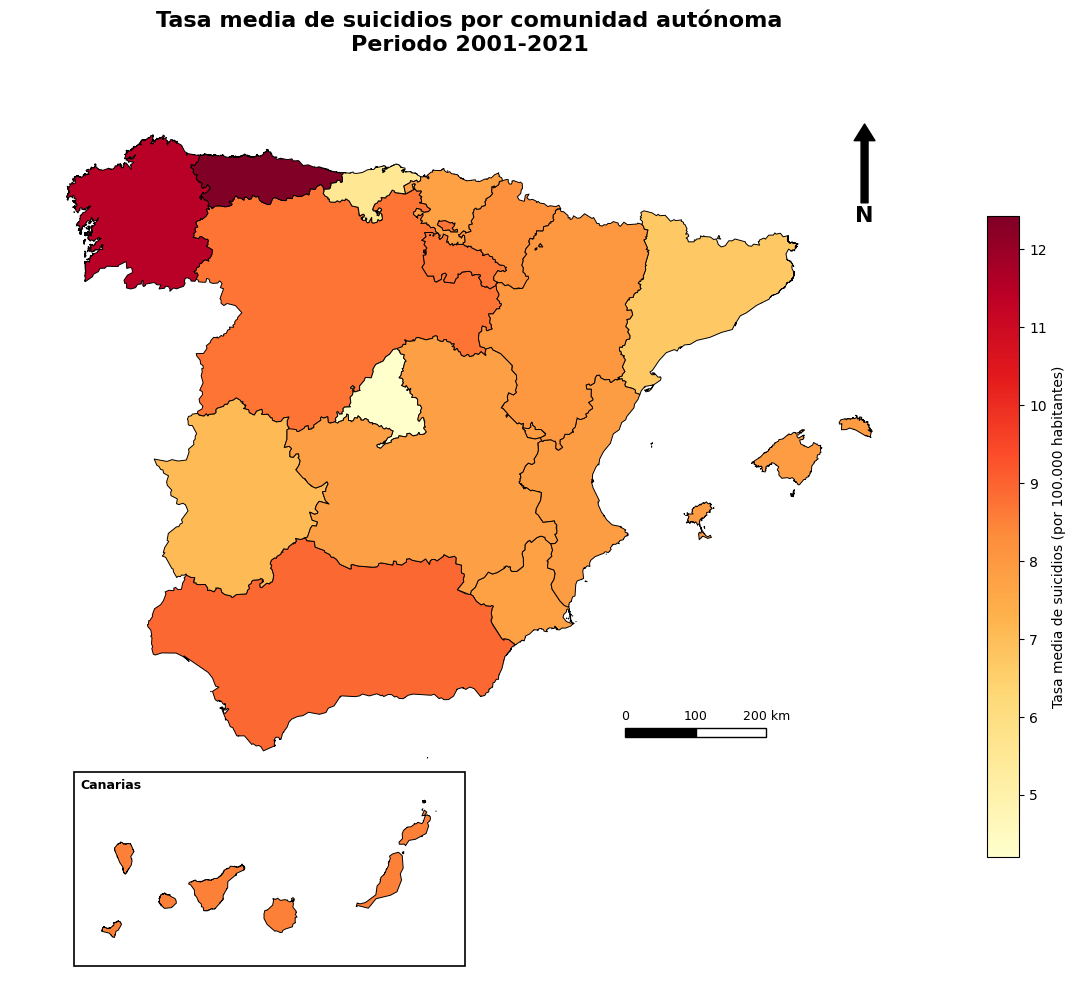


Análisis finalizado correctamente.


In [9]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon
import unicodedata

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("spain_suicide_rate.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["Periodo"] >= 2001) & (df["Periodo"] <= 2021)]

print("Años disponibles:", df["Periodo"].nunique())
print("Territorios disponibles:", df["Comunidades y Ciudades Autónomas"].nunique())

# --------------------------------------------------
# 2. FUNCIÓN PARA UNIFICAR NOMBRES (CSV Y GEOJSON)
# --------------------------------------------------

def clave(nombre):
    n = str(nombre).lower().strip()
    n = unicodedata.normalize("NFKD", n)
    n = "".join(c for c in n if not unicodedata.combining(c))
    n = n.replace("-", " ").replace("_", " ")

    # Se busca una palabra clave de cada comunidad (el orden importa)
    if "mancha" in n:   return "castilla la mancha"
    if "leon" in n:     return "castilla y leon"
    if "andalu" in n:   return "andalucia"
    if "arag" in n:     return "aragon"
    if "asturi" in n:   return "asturias"
    if "balear" in n:   return "baleares"
    if "canari" in n:   return "canarias"
    if "cantabri" in n: return "cantabria"
    if "catal" in n:    return "cataluna"
    if "valenc" in n:   return "valencia"
    if "extremadura" in n: return "extremadura"
    if "galicia" in n:  return "galicia"
    if "madrid" in n:   return "madrid"
    if "murcia" in n:   return "murcia"
    if "navarr" in n:   return "navarra"
    if "vasco" in n or "basque" in n or "euskadi" in n: return "pais vasco"
    if "rioja" in n:    return "la rioja"
    if "ceuta" in n:    return "ceuta"
    if "melilla" in n:  return "melilla"
    return n

df["clave"] = df["Comunidades y Ciudades Autónomas"].apply(clave)

# Quitar Ceuta y Melilla
df = df[~df["clave"].isin(["ceuta", "melilla"])]

# --------------------------------------------------
# 3. CALCULAR LA TASA MEDIA 2001-2021
# --------------------------------------------------

tasa = (
    df.groupby("clave")["suicides_per_10k"]
    .mean()
    .reset_index()
)

# Se pasa a tasa por 100.000 habitantes (unidad habitual en epidemiología)
tasa["tasa_media"] = tasa["suicides_per_10k"] * 10

print("\nTasa media de suicidios (por 100.000 hab.), 2001-2021:")
print(tasa.sort_values("tasa_media", ascending=False)[["clave", "tasa_media"]])

# --------------------------------------------------
# 4. CARGAR EL MAPA DE COMUNIDADES AUTÓNOMAS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)
mapa["clave"] = mapa["name"].apply(clave)

# Quitar Ceuta y Melilla del mapa
mapa = mapa[~mapa["clave"].isin(["ceuta", "melilla"])]

# --------------------------------------------------
# 5. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    tasa[["clave", "tasa_media"]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[mapa_final["tasa_media"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 6. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

# Península + Baleares en ETRS89 / UTM 30N (metros)
pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)

# Canarias en WGS84 / UTM 28N (metros)
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

margen = 40_000
separacion = 60_000

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

dx = destino_minx - can_minx
dy = destino_maxy - can_maxy

can["geometry"] = can.geometry.translate(xoff=dx, yoff=dy)
can = can.set_crs(pen.crs, allow_override=True)

mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 7. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))

mapa_plot.plot(
    column="tasa_media",
    cmap="YlOrRd",
    linewidth=0.7,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Tasa media de suicidios (por 100.000 habitantes)",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False,
    edgecolor="black",
    linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000,
    cy1 + margen - 10_000,
    "Canarias",
    fontsize=9,
    fontweight="bold",
    va="top"
)

# ---- Barra de escala (200 km, en tramos de 100 km) ----
sb_x0 = pen_maxx - 350_000
sb_y0 = pen_miny + 30_000
tramo = 100_000
alto = 12_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0),
        tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black",
        linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo,
        sb_y0 + alto + 8_000,
        etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte ----
ax.annotate(
    "N",
    xy=(0.93, 0.95),
    xytext=(0.93, 0.85),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    arrowprops=dict(facecolor="black", width=5, headwidth=15)
)

# Límites para que quepa todo
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

ax.set_title(
    "Tasa media de suicidios por comunidad autónoma\n"
    "Periodo 2001-2021",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig(
    "mapa_suicidios_2001_2021.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 8. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

tasa[["clave", "tasa_media"]].to_csv(
    "tasa_media_suicidios_por_comunidad.csv",
    index=False
)

print("\nAnálisis finalizado correctamente.")

Map of US states, precipitation hours

Años disponibles: 21
Estados disponibles: 51

Media de horas de precipitación:
                  estado  media_horas_precipitacion
11                Hawaii                2959.640000
48         West Virginia                1667.563810
47            Washington                1643.931905
32              New York                1636.089524
45               Vermont                1627.795238
1                 Alaska                1603.160000
38          Pennsylvania                1467.310000
29         New Hampshire                1446.986190
19                 Maine                1433.300476
35                  Ohio                1374.578571
37                Oregon                1364.771905
17              Kentucky                1331.790000
42             Tennessee                1325.304286
21         Massachusetts                1284.702381
22              Michigan                1279.301429
33        North Carolina                1275.050476
6            Connecticut             

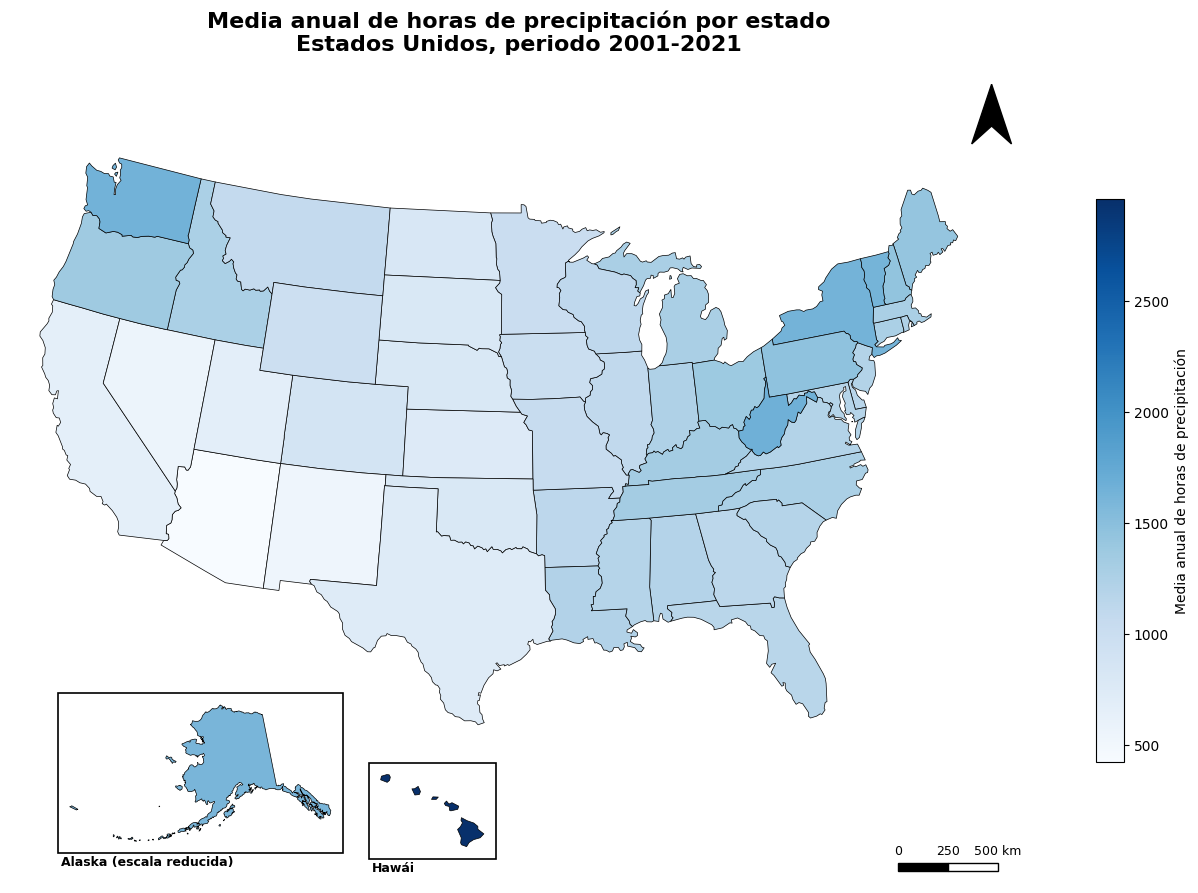


Análisis finalizado correctamente.


In [30]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["precipitation_hours"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "media_horas_precipitacion"]

print("\nMedia de horas de precipitación:")
print(media_precipitacion.sort_values(
    "media_horas_precipitacion", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["media_horas_precipitacion"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="media_horas_precipitacion",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Media anual de horas de precipitación",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media anual de horas de precipitación por estado\n"
    "Estados Unidos, periodo 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_horas_precipitaciones_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_horas_precipitaciones_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Map of US states, precipitation accumulation

Años disponibles: 21
Estados disponibles: 51

Media de litros acumulados:
                  estado  media_litros_acumulados
11                Hawaii              1989.561905
18             Louisiana              1317.288095
24           Mississippi              1315.454286
42             Tennessee              1265.234762
0                Alabama              1261.408095
3               Arkansas              1223.989524
17              Kentucky              1210.747143
33        North Carolina              1181.788095
48         West Virginia              1174.216190
40        South Carolina              1135.167619
9                Florida              1113.030000
10               Georgia              1103.993333
7               Delaware              1091.054286
20              Maryland              1065.564286
6            Connecticut              1062.308571
30            New Jersey              1060.251429
39          Rhode Island              1050.374286
38          Pennsylvania  

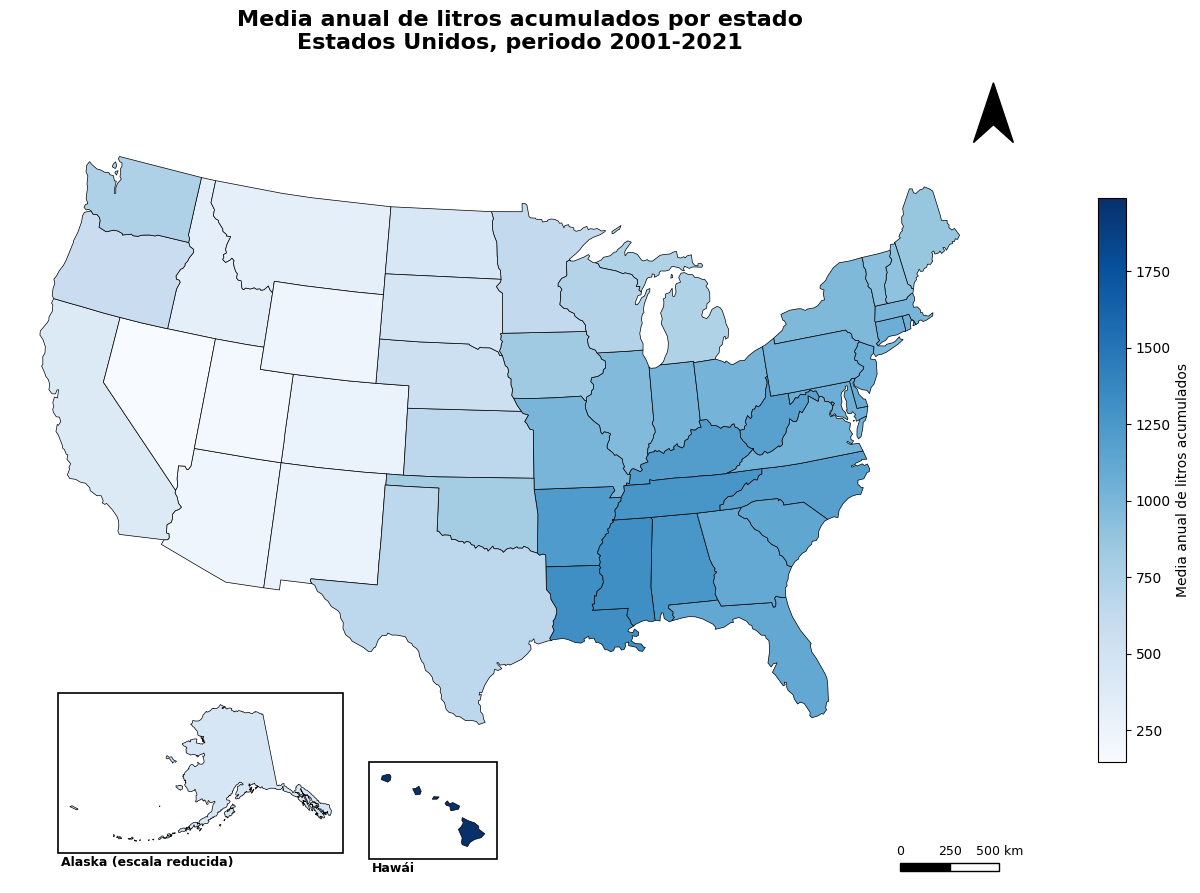


Análisis finalizado correctamente.


In [18]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["rain_sum"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "media_litros_acumulados"]

print("\nMedia de litros acumulados:")
print(media_precipitacion.sort_values(
    "media_litros_acumulados", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["media_litros_acumulados"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="media_litros_acumulados",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Media anual de litros acumulados",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media anual de litros acumulados por estado\n"
    "Estados Unidos, periodo 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_litros_acumulados_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_litros_acumulados_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Map of US states, average temperature

Años disponibles: 21
Estados disponibles: 51

Average temperature:
                  estado  average_temperature
9                Florida            22.080952
18             Louisiana            19.991905
11                Hawaii            19.286667
43                 Texas            19.276667
24           Mississippi            18.471905
10               Georgia            18.450476
0                Alabama            18.240952
40        South Carolina            17.882857
2                Arizona            17.146667
3               Arkansas            16.832381
36              Oklahoma            16.327143
33        North Carolina            15.860952
42             Tennessee            15.539524
4             California            15.078571
17              Kentucky            14.390476
7               Delaware            14.226190
8   District of Columbia            14.110476
20              Maryland            14.055714
46              Virginia            13.974286
25           

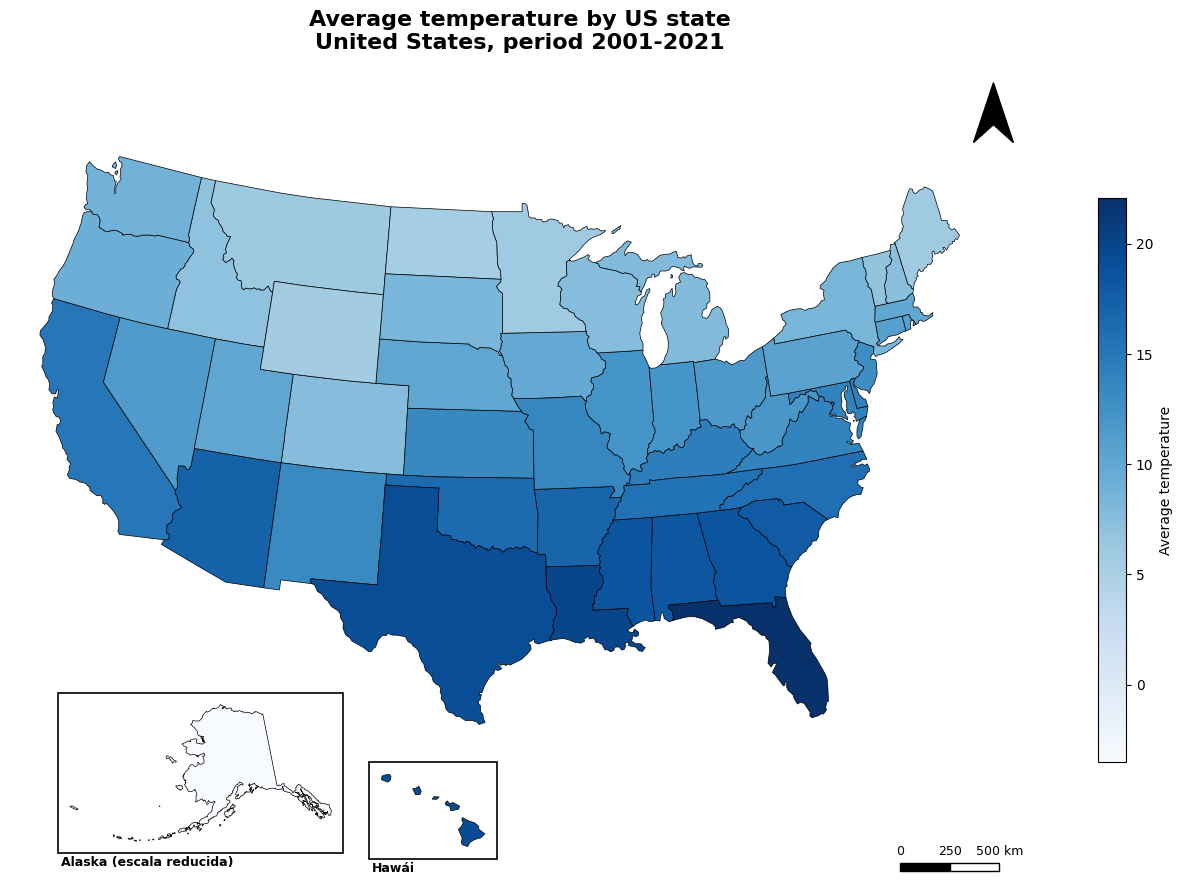


Análisis finalizado correctamente.


In [19]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["temperature_2m_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "average_temperature"]

print("\nAverage temperature:")
print(media_precipitacion.sort_values(
    "average_temperature", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["average_temperature"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="average_temperature",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Average temperature",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Average temperature by US state\n"
    "United States, period 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_temperatura_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_temperatura_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Map of US states, daylight duration

Años disponibles: 21
Estados disponibles: 51

Average daylight duration:
                  estado  average_daylight
1                 Alaska      45069.234762
47            Washington      44068.422381
34          North Dakota      44068.263810
26               Montana      44059.622381
23             Minnesota      44045.550952
19                 Maine      44023.275714
49             Wisconsin      44009.067619
12                 Idaho      44004.059524
22              Michigan      44003.841905
41          South Dakota      44003.397143
45               Vermont      43996.720952
37                Oregon      43994.424286
29         New Hampshire      43989.357143
50               Wyoming      43977.564286
32              New York      43975.638095
21         Massachusetts      43962.718571
15                  Iowa      43961.407143
39          Rhode Island      43954.141905
6            Connecticut      43953.161429
27              Nebraska      43951.943333
38          Pennsylvania

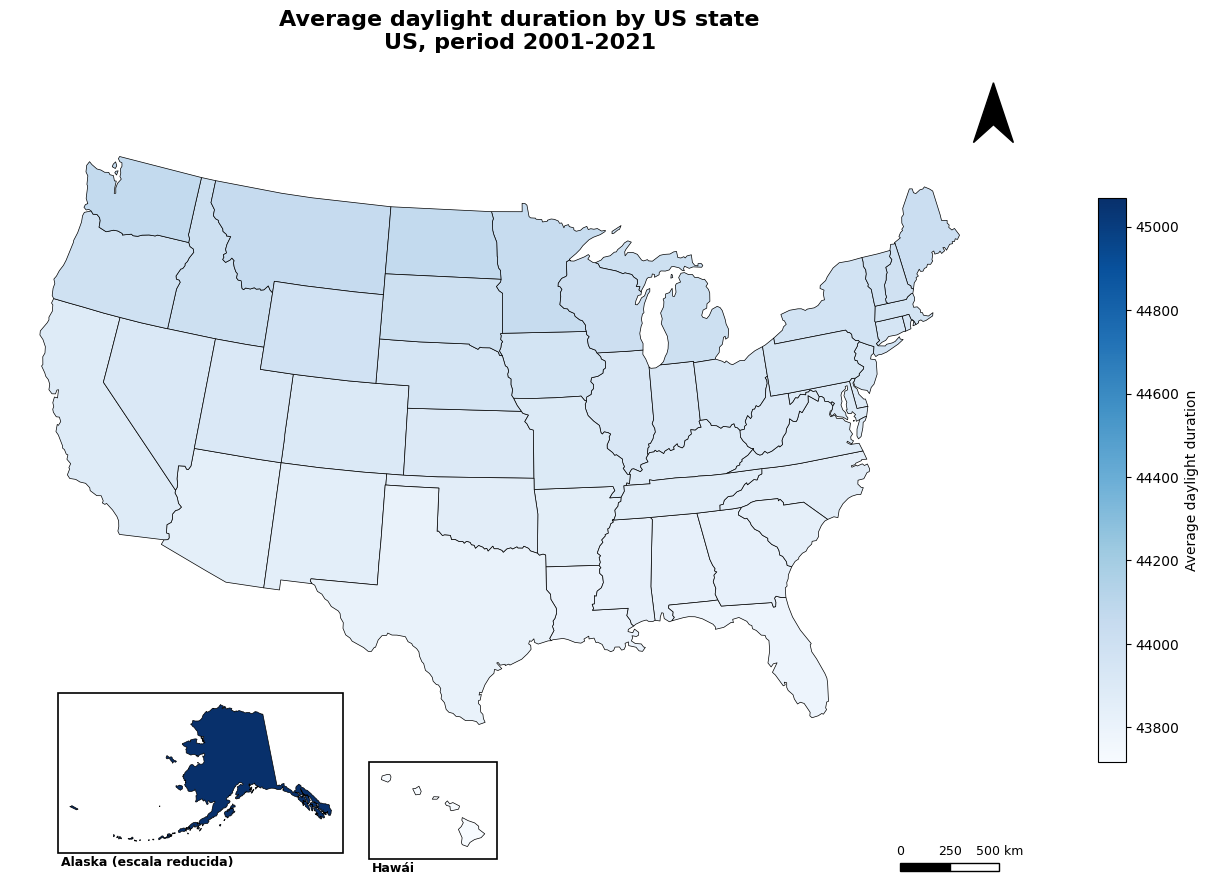


Análisis finalizado correctamente.


In [20]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["daylight_duration"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "average_daylight"]

print("\nAverage daylight duration:")
print(media_precipitacion.sort_values(
    "average_daylight", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["average_daylight"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="average_daylight",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Average daylight duration",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Average daylight duration by US state\n"
    "US, period 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_daylight_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_daylight_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Map of suicide rates by US state

Años disponibles: 21
Estados disponibles: 51

Tasa media de suicidios (por 100.000 hab.), 2001-2021:
                  estado  tasa_media
50               Wyoming   23.581429
26               Montana   23.469524
1                 Alaska   23.276667
31            New Mexico   21.091429
28                Nevada   19.872381
5               Colorado   19.032381
12                 Idaho   18.599524
37                Oregon   17.695714
2                Arizona   17.582381
44                  Utah   17.539524
36              Oklahoma   17.433810
48         West Virginia   17.188095
41          South Dakota   17.062381
3               Arkansas   16.422381
45               Vermont   16.192381
19                 Maine   15.783810
34          North Dakota   15.736190
25              Missouri   15.489524
17              Kentucky   15.476667
42             Tennessee   15.290000
16                Kansas   15.143810
29         New Hampshire   14.888095
9                Florida   14.841905
47         

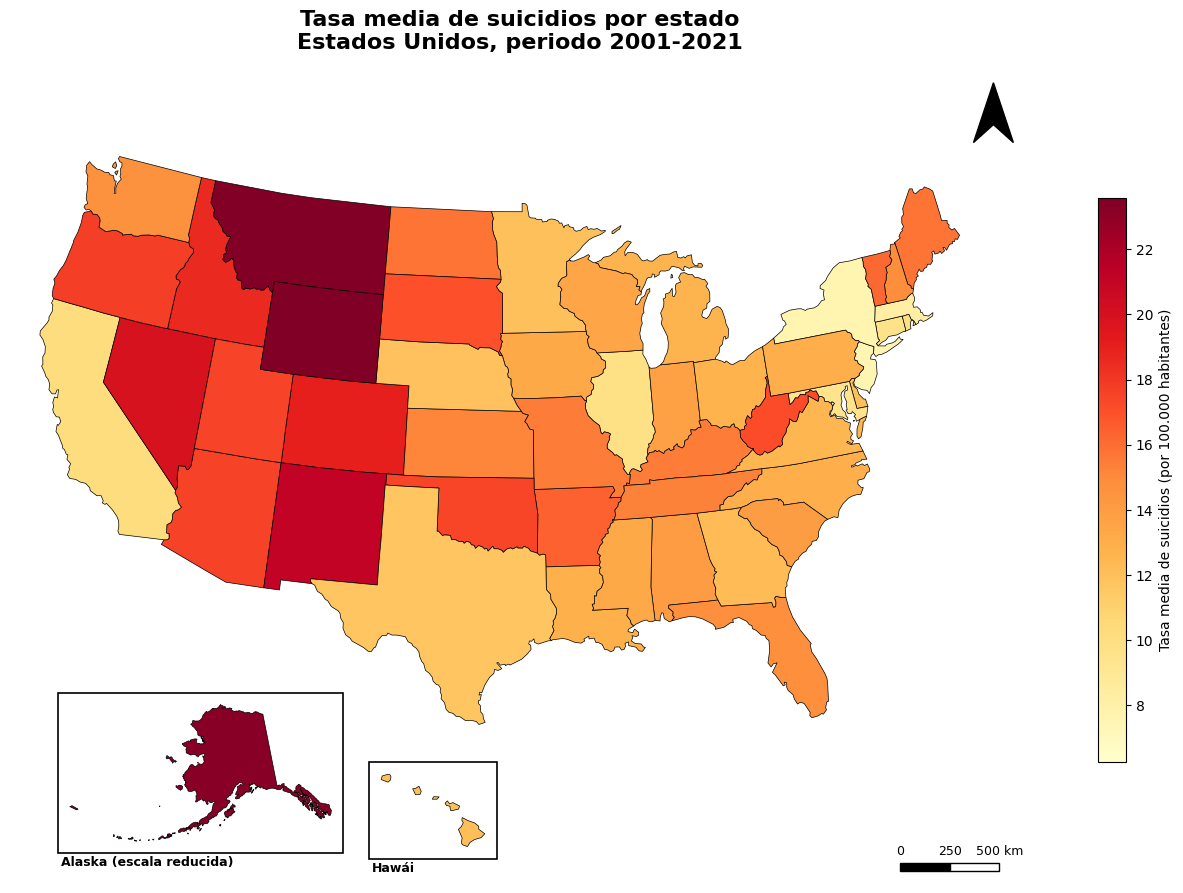


Análisis finalizado correctamente.


In [21]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_suicide_rate.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["Year"] >= 2001) & (df["Year"] <= 2021)]

print("Años disponibles:", df["Year"].nunique())
print("Estados disponibles:", df["Location"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA TASA MEDIA 2001-2021
# --------------------------------------------------

# Se usa suicides_per_10k (tasa bruta, homogénea en todos los años).
# La columna "Age-Adjusted Death Rate" mezcla tasa bruta (2001-2013)
# y ajustada por edad (2014-2021), por eso no se utiliza.
tasa = (
    df.groupby("Location")["suicides_per_10k"]
    .mean()
    .reset_index()
)

# Se pasa a tasa por 100.000 habitantes
tasa["tasa_media"] = tasa["suicides_per_10k"] * 10
tasa = tasa.rename(columns={"Location": "estado"})

print("\nTasa media de suicidios (por 100.000 hab.), 2001-2021:")
print(tasa.sort_values("tasa_media", ascending=False)[["estado", "tasa_media"]])

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    tasa[["estado", "tasa_media"]],
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["tasa_media"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="tasa_media",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Tasa media de suicidios (por 100.000 habitantes)",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Tasa media de suicidios por estado\n"
    "Estados Unidos, periodo 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_suicidios_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

tasa[["estado", "tasa_media"]].to_csv(
    "tasa_media_suicidios_por_estado.csv", index=False
)

print("\nAnálisis finalizado correctamente.")

Map of US states by cloud cover.

Años disponibles: 21
Estados disponibles: 51

Media de nubosidad:
                  estado  media_nubosidad
1                 Alaska        71.675714
32              New York        64.790952
45               Vermont        64.294286
22              Michigan        63.774286
38          Pennsylvania        63.325714
19                 Maine        62.854286
29         New Hampshire        62.011429
48         West Virginia        61.720952
35                  Ohio        61.700952
49             Wisconsin        60.999048
23             Minnesota        60.313333
14               Indiana        59.476667
47            Washington        59.445238
21         Massachusetts        58.608571
6            Connecticut        58.211429
17              Kentucky        58.037619
39          Rhode Island        57.776190
30            New Jersey        57.512857
13              Illinois        56.908095
8   District of Columbia        56.754286
46              Virginia        56.464286
20        

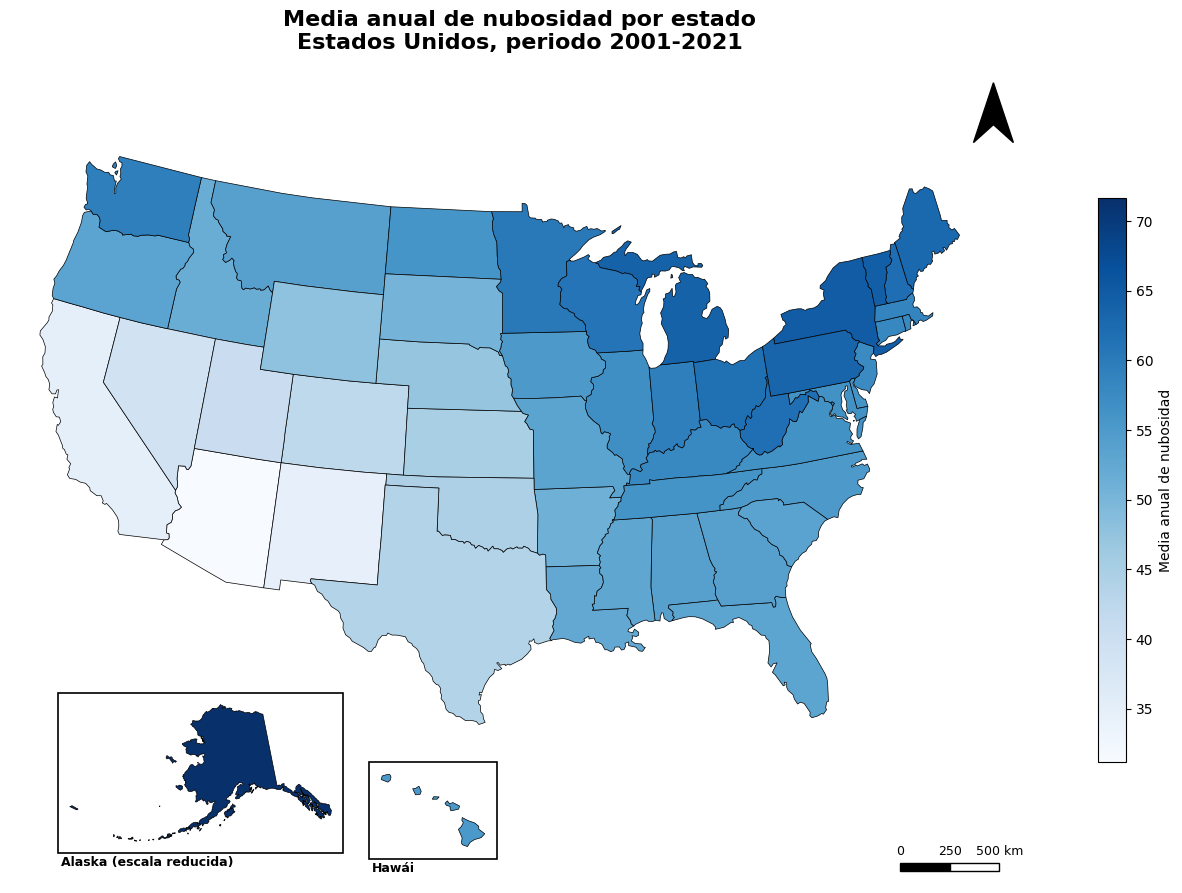


Análisis finalizado correctamente.


In [29]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["cloud_cover_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "media_nubosidad"]

print("\nMedia de nubosidad:")
print(media_precipitacion.sort_values(
    "media_nubosidad", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["media_nubosidad"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="media_nubosidad",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Media anual de nubosidad",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media anual de nubosidad por estado\n"
    "Estados Unidos, periodo 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_nubosidad_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_nubosidad_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Map wind US states

Años disponibles: 21
Estados disponibles: 51

Media de viento:
                  estado  media_viento
27              Nebraska     25.936667
34          North Dakota     25.667619
41          South Dakota     25.355714
16                Kansas     24.627143
15                  Iowa     24.495238
36              Oklahoma     23.028095
23             Minnesota     23.015238
43                 Texas     22.606667
22              Michigan     22.251429
39          Rhode Island     22.192857
21         Massachusetts     21.639524
49             Wisconsin     21.615714
13              Illinois     21.373810
14               Indiana     21.235714
7               Delaware     20.847619
19                 Maine     20.837143
35                  Ohio     20.671905
32              New York     20.271905
25              Missouri     20.240476
6            Connecticut     20.233810
30            New Jersey     20.090000
50               Wyoming     20.020000
20              Maryland     19.862381
2

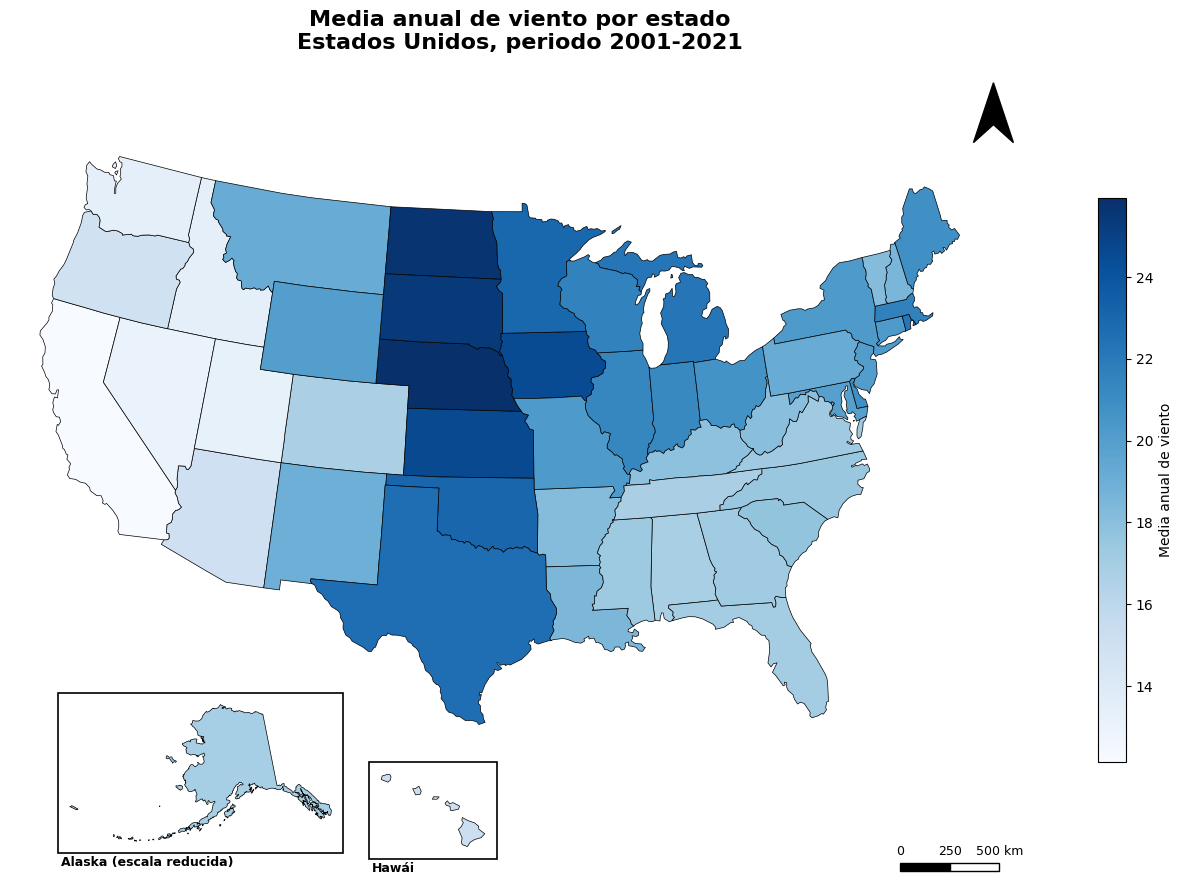


Análisis finalizado correctamente.


In [36]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# 1. CARGAR LOS DATOS
# --------------------------------------------------

df = pd.read_csv("usa_yearly.csv")

# Seleccionar el periodo 2001-2021
df = df[(df["year"] >= 2001) & (df["year"] <= 2021)]

print("Años disponibles:", df["year"].nunique())
print("Estados disponibles:", df["region_name"].nunique())

# --------------------------------------------------
# 2. CALCULAR LA MEDIA DE HORAS DE PRECIPITACIÓN
# --------------------------------------------------

media_precipitacion = (
    df.groupby("region_name")["wind_speed_100m_mean"]
    .mean()
    .reset_index()
)

media_precipitacion.columns = ["estado", "media_viento"]

print("\nMedia de viento:")
print(media_precipitacion.sort_values(
    "media_viento", ascending=False
))

# --------------------------------------------------
# 3. CARGAR EL MAPA DE ESTADOS
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

mapa = gpd.read_file(url)

# Quitar Puerto Rico (no está en el CSV)
mapa = mapa[mapa["name"] != "Puerto Rico"]

# --------------------------------------------------
# 4. UNIR EL MAPA CON LOS DATOS
# --------------------------------------------------

mapa_final = mapa.merge(
    media_precipitacion,
    left_on="name",
    right_on="estado",
    how="left"
)

sin_datos = mapa_final[mapa_final["media_viento"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: estados sin correspondencia:")
    print(sin_datos["name"].tolist())

# --------------------------------------------------
# 5. REPROYECTAR Y COLOCAR ALASKA Y HAWÁI COMO RECUADROS
# --------------------------------------------------

CRS_PLOT = 5070  # NAD83 / Conus Albers (metros)

# Estados contiguos + DC
con = mapa_final[~mapa_final["name"].isin(["Alaska", "Hawaii"])].to_crs(CRS_PLOT)

# Alaska (Alaska Albers) y Hawái (Albers centrado en Hawái)
ak = mapa_final[mapa_final["name"] == "Alaska"].to_crs(3338).copy()
hi = mapa_final[mapa_final["name"] == "Hawaii"].to_crs(
    "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
    "+datum=NAD83 +units=m +no_defs"
).copy()

# Alaska se reduce (es enorme); Hawái se mantiene a escala real
FACTOR_AK = 0.35
ak["geometry"] = ak.geometry.scale(
    xfact=FACTOR_AK, yfact=FACTOR_AK, origin="center"
)

con_minx, con_miny, con_maxx, con_maxy = con.total_bounds

def colocar(gdf, x_izq, y_arriba):
    """Traslada gdf para que su esquina superior-izquierda quede en (x_izq, y_arriba)."""
    minx, miny, maxx, maxy = gdf.total_bounds
    gdf["geometry"] = gdf.geometry.translate(
        xoff=x_izq - minx, yoff=y_arriba - maxy
    )
    return gdf.set_crs(CRS_PLOT, allow_override=True)

y_top = con_miny + 100_000   # altura superior de los recuadros

ak = colocar(ak, con_minx + 150_000, y_top)
ak_minx, ak_miny, ak_maxx, ak_maxy = ak.total_bounds

bajada_hawai = 350_000   # cuánto se baja Hawái respecto a Alaska (m)
hi = colocar(hi, ak_maxx + 250_000, y_top - bajada_hawai)
hi_minx, hi_miny, hi_maxx, hi_maxy = hi.total_bounds

mapa_plot = gpd.GeoDataFrame(
    pd.concat([con, ak, hi], ignore_index=True), crs=CRS_PLOT
)

# --------------------------------------------------
# 6. REPRESENTAR EL MAPA COROPLÉTICO
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 9))

mapa_plot.plot(
    column="media_viento",
    cmap="Blues",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    legend_kwds={
        "label": "Media anual de viento",
        "orientation": "vertical",
        "shrink": 0.7
    },
    ax=ax
)

# ---- Recuadros de Alaska y Hawái ----
margen = 60_000

def recuadro(minx, miny, maxx, maxy, texto):
    ax.add_patch(Rectangle(
        (minx - margen, miny - margen),
        (maxx - minx) + 2 * margen,
        (maxy - miny) + 2 * margen,
        fill=False, edgecolor="black", linewidth=1.2
    ))
    ax.text(
        minx - margen + 15_000, miny - margen - 15_000, texto,
        fontsize=9, fontweight="bold", va="top"
    )

recuadro(ak_minx, ak_miny, ak_maxx, ak_maxy, "Alaska (escala reducida)")
recuadro(hi_minx, hi_miny, hi_maxx, hi_maxy, "Hawái")

# Límites con margen extra arriba y a la derecha para que quepa la flecha
ax.set_xlim(con_minx - 150_000, con_maxx + 350_000)
ax.set_ylim(ak_miny - margen - 150_000, con_maxy + 400_000)

# Esquinas reales del mapa (se usan para anclar escala y flecha)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (500 km) ----
tramo = 250_000
alto = 40_000
sb_x0 = xmax - 2 * tramo - 150_000
sb_y0 = ymin + 60_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "250", "500 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 25_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 300_000      # altura de la flecha (m)
ancho_flecha = 200_000     # anchura de la flecha (m)
fx = xmax - 180_000        # centro horizontal
fy = ymax - 30_000         # punta de la flecha

ax.add_patch(Polygon(
    [
        (fx, fy),                                    # punta
        (fx + ancho_flecha / 2, fy - alto_flecha),   # esquina inferior derecha
        (fx, fy - 0.7 * alto_flecha),                # muesca central
        (fx - ancho_flecha / 2, fy - alto_flecha),   # esquina inferior izquierda
    ],
    closed=True,
    facecolor="black",
    edgecolor="black",
    linewidth=1
))

ax.set_title(
    "Media anual de viento por estado\n"
    "Estados Unidos, periodo 2001-2021",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig("mapa_viento_eeuu_2001_2021.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 7. EXPORTAR LOS RESULTADOS
# --------------------------------------------------

media_precipitacion.to_csv("media_viento_por_estado.csv", index=False)

print("\nAnálisis finalizado correctamente.")

Calculation of R^2 for two desired sets of data. We compare this way the correlation of suicide with weather in US and Spain

Elige el PRIMER archivo CSV (escribe la ruta del archivo): /content/tasa_media_suicidios_por_estado.csv
Elige el SEGUNDO archivo CSV (escribe la ruta del archivo): /content/media_viento_por_estado.csv

X: tasa_media
Y: media_viento
Territorios en común (n): 51
R²:                       0.0534
r de Pearson:             -0.2310
Pendiente:                -0.1960
p-valor:                  0.1029


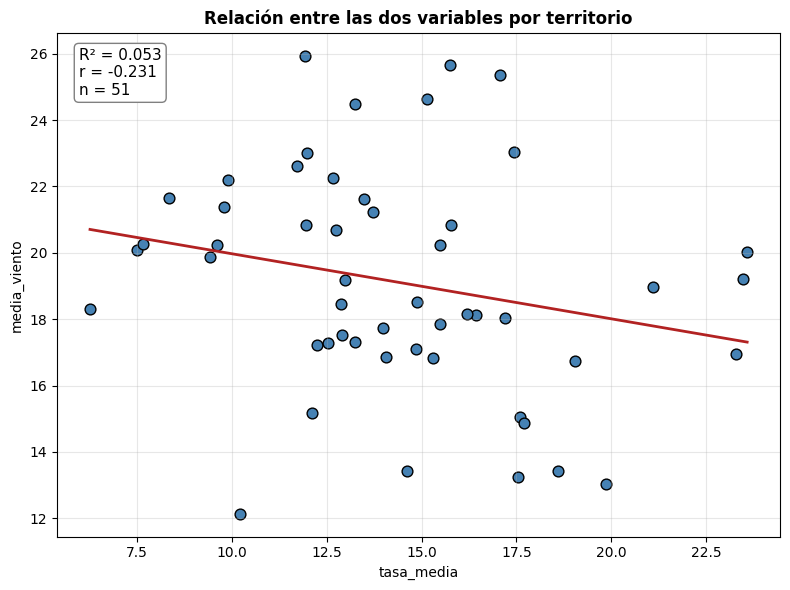


Guardado: regresion_r2.png y datos_unidos_r2.csv


In [37]:
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# --------------------------------------------------
# 1. ELEGIR ARCHIVOS
# --------------------------------------------------

def elegir_archivo(titulo):
    """Abre una ventana para elegir un CSV. Si no hay entorno gráfico, pide la ruta por teclado."""
    try:
        import tkinter as tk
        from tkinter import filedialog

        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        ruta = filedialog.askopenfilename(
            title=titulo,
            filetypes=[("Archivos CSV", "*.csv"), ("Todos los archivos", "*.*")]
        )
        root.destroy()
    except Exception:
        ruta = input(f"{titulo} (escribe la ruta del archivo): ").strip().strip('"')

    if not ruta:
        raise SystemExit("No se ha seleccionado ningún archivo.")
    return ruta


# --------------------------------------------------
# 2. UNIFICAR NOMBRES DE TERRITORIOS
# --------------------------------------------------

def clave(nombre):
    """Normaliza nombres (sin tildes, minúsculas) y unifica variantes de las CCAA españolas.
    Para estados de EEUU solo normaliza el texto."""
    n = str(nombre).lower().strip()
    n = unicodedata.normalize("NFKD", n)
    n = "".join(c for c in n if not unicodedata.combining(c))
    n = n.replace("-", " ").replace("_", " ")

    if "mancha" in n:   return "castilla la mancha"
    if "leon" in n:     return "castilla y leon"
    if "andalu" in n:   return "andalucia"
    if "arag" in n:     return "aragon"
    if "asturi" in n:   return "asturias"
    if "balear" in n:   return "baleares"
    if "canar" in n:    return "canarias"
    if "cantabri" in n: return "cantabria"
    if "catal" in n:    return "cataluna"
    if "valenc" in n:   return "valencia"
    if "extremadura" in n: return "extremadura"
    if "galicia" in n:  return "galicia"
    if "madrid" in n:   return "madrid"
    if "murcia" in n:   return "murcia"
    if "navarr" in n:   return "navarra"
    if "vasco" in n or "basque" in n or "euskadi" in n: return "pais vasco"
    if "rioja" in n:    return "la rioja"
    if "ceuta" in n:    return "ceuta"
    if "melilla" in n:  return "melilla"
    return n


# --------------------------------------------------
# 3. CARGAR UN CSV (columna de nombres + columna de valores)
# --------------------------------------------------

def cargar(ruta):
    df = pd.read_csv(ruta)

    cols_txt = df.select_dtypes(exclude="number").columns.tolist()
    cols_num = df.select_dtypes(include="number").columns.tolist()

    if not cols_txt or not cols_num:
        raise ValueError(
            f"{os.path.basename(ruta)} necesita una columna de nombres "
            "y al menos una columna numérica."
        )

    col_nombre = cols_txt[0]

    if len(cols_num) == 1:
        col_valor = cols_num[0]
    else:
        print(f"\n{os.path.basename(ruta)} tiene varias columnas numéricas:")
        for i, c in enumerate(cols_num):
            print(f"  [{i}] {c}")
        col_valor = cols_num[int(input("Elige el número de la variable: "))]

    df["_clave"] = df[col_nombre].apply(clave)
    df = df.groupby("_clave", as_index=False)[col_valor].mean()

    return df, col_valor


# --------------------------------------------------
# 4. PROGRAMA PRINCIPAL
# --------------------------------------------------

def main():
    ruta_a = elegir_archivo("Elige el PRIMER archivo CSV")
    ruta_b = elegir_archivo("Elige el SEGUNDO archivo CSV")

    a, var_a = cargar(ruta_a)
    b, var_b = cargar(ruta_b)

    # Si las dos variables se llaman igual, se distinguen con el nombre del archivo
    if var_a == var_b:
        var_a = f"{var_a} ({os.path.basename(ruta_a)})"
        var_b = f"{var_b} ({os.path.basename(ruta_b)})"

    a = a.rename(columns={a.columns[1]: "x"})
    b = b.rename(columns={b.columns[1]: "y"})

    datos = a.merge(b, on="_clave", how="inner").dropna(subset=["x", "y"])

    # Territorios que no coinciden entre archivos
    solo_a = sorted(set(a["_clave"]) - set(b["_clave"]))
    solo_b = sorted(set(b["_clave"]) - set(a["_clave"]))
    if solo_a:
        print("\nSolo en el primer archivo (excluidos):", solo_a)
    if solo_b:
        print("Solo en el segundo archivo (excluidos):", solo_b)

    n = len(datos)
    if n < 3:
        raise SystemExit(
            f"Solo hay {n} territorios en común: no se puede calcular la R². "
            "Revisa que los dos archivos sean del mismo país."
        )

    # ---- Regresión lineal ----
    res = stats.linregress(datos["x"], datos["y"])
    r2 = res.rvalue ** 2

    print("\n" + "=" * 50)
    print(f"X: {var_a}")
    print(f"Y: {var_b}")
    print(f"Territorios en común (n): {n}")
    print(f"R²:                       {r2:.4f}")
    print(f"r de Pearson:             {res.rvalue:.4f}")
    print(f"Pendiente:                {res.slope:.4f}")
    print(f"p-valor:                  {res.pvalue:.4g}")
    print("=" * 50)

    # ---- Gráfico de dispersión con la recta ----
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(datos["x"], datos["y"], color="steelblue", edgecolor="black", s=60)

    xs = np.linspace(datos["x"].min(), datos["x"].max(), 100)
    ax.plot(xs, res.intercept + res.slope * xs, color="firebrick", linewidth=2)

    # Etiquetas de los puntos solo si no hay demasiados
    if n <= 20:
        for _, fila in datos.iterrows():
            ax.annotate(
                fila["_clave"], (fila["x"], fila["y"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8
            )

    ax.text(
        0.03, 0.97,
        f"R² = {r2:.3f}\nr = {res.rvalue:.3f}\nn = {n}",
        transform=ax.transAxes, va="top", fontsize=11,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey")
    )

    ax.set_xlabel(var_a)
    ax.set_ylabel(var_b)
    ax.set_title("Relación entre las dos variables por territorio", fontweight="bold")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("regresion_r2.png", dpi=300, bbox_inches="tight")
    plt.show()

    # ---- Guardar la tabla unida ----
    datos.rename(columns={"_clave": "territorio", "x": var_a, "y": var_b}).to_csv(
        "datos_unidos_r2.csv", index=False
    )

    print("\nGuardado: regresion_r2.png y datos_unidos_r2.csv")


if __name__ == "__main__":
    main()

Bivariate map for Spain. Suicide and precipitation hours. (Check if it works)

Comunidades con ambos datos: 17
             clave  precipitation_hours  tasa_suicidios
          asturias          2193.840476       12.431429
           galicia          1842.459048       11.446667
         andalucia           773.963333        8.904762
   castilla y leon          1151.822381        8.707619
          la rioja          1404.707619        8.647143
          canarias           380.471905        8.533333
           navarra          1444.766667        8.190000
            aragon           917.027143        8.026667
          baleares           704.268571        7.908095
          valencia           761.013333        7.877143
castilla la mancha           854.774286        7.806190
        pais vasco          1931.740000        7.747143
            murcia           591.478095        7.741905
       extremadura           836.772381        7.088095
          cataluna          1095.566667        6.704762
         cantabria          2158.795714        5.539524
            madr

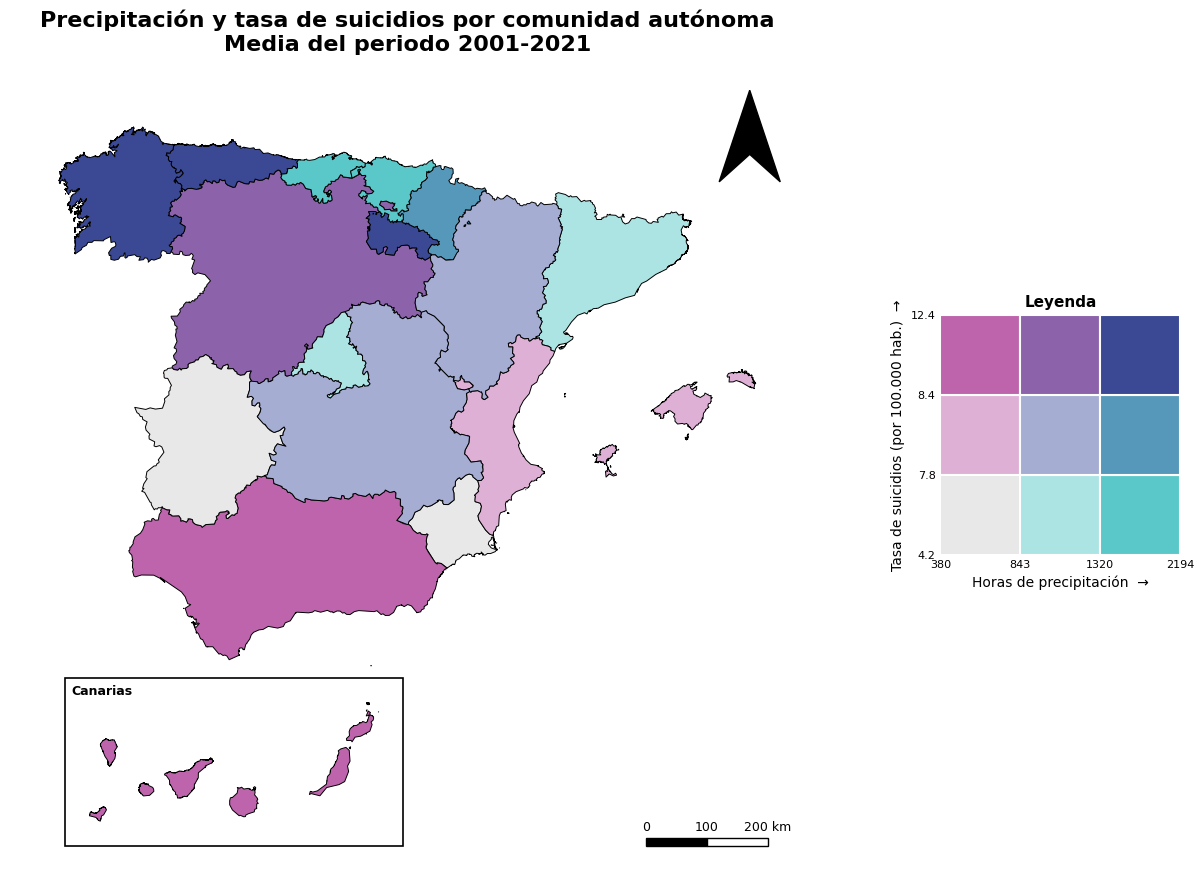


Análisis finalizado correctamente.


In [38]:
import unicodedata

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

# --------------------------------------------------
# CONFIGURACIÓN
# --------------------------------------------------

ARCHIVO_CLIMA = "spain_yearly.csv"
ARCHIVO_SUICIDIOS = "spain_suicide_rate.csv"
ANIO_INI, ANIO_FIN = 2001, 2021

# Paleta bivariada 3x3 (J. Stevens). Clave = (clase de precipitación, clase de suicidios)
# Precipitación: de gris a turquesa  |  Suicidios: de gris a morado
PALETA = {
    (0, 0): "#e8e8e8", (1, 0): "#ace4e4", (2, 0): "#5ac8c8",
    (0, 1): "#dfb0d6", (1, 1): "#a5add3", (2, 1): "#5698b9",
    (0, 2): "#be64ac", (1, 2): "#8c62aa", (2, 2): "#3b4994",
}

# --------------------------------------------------
# 1. FUNCIÓN PARA UNIFICAR NOMBRES DE COMUNIDADES
# --------------------------------------------------

def clave(nombre):
    n = str(nombre).lower().strip()
    n = unicodedata.normalize("NFKD", n)
    n = "".join(c for c in n if not unicodedata.combining(c))
    n = n.replace("-", " ").replace("_", " ")

    if "mancha" in n:   return "castilla la mancha"
    if "leon" in n:     return "castilla y leon"
    if "andalu" in n:   return "andalucia"
    if "arag" in n:     return "aragon"
    if "asturi" in n:   return "asturias"
    if "balear" in n:   return "baleares"
    if "canar" in n:    return "canarias"
    if "cantabri" in n: return "cantabria"
    if "catal" in n:    return "cataluna"
    if "valenc" in n:   return "valencia"
    if "extremadura" in n: return "extremadura"
    if "galicia" in n:  return "galicia"
    if "madrid" in n:   return "madrid"
    if "murcia" in n:   return "murcia"
    if "navarr" in n:   return "navarra"
    if "vasco" in n or "basque" in n or "euskadi" in n: return "pais vasco"
    if "rioja" in n:    return "la rioja"
    if "ceuta" in n:    return "ceuta"
    if "melilla" in n:  return "melilla"
    return n

# --------------------------------------------------
# 2. DATOS DE PRECIPITACIÓN (media 2001-2021)
# --------------------------------------------------

clima = pd.read_csv(ARCHIVO_CLIMA)
clima = clima[(clima["year"] >= ANIO_INI) & (clima["year"] <= ANIO_FIN)]
clima["clave"] = clima["region_name"].apply(clave)

precip = (
    clima.groupby("clave", as_index=False)["precipitation_hours"].mean()
)

# --------------------------------------------------
# 3. DATOS DE SUICIDIOS (media 2001-2021, por 100.000 hab.)
# --------------------------------------------------

suic = pd.read_csv(ARCHIVO_SUICIDIOS)
suic = suic[(suic["Periodo"] >= ANIO_INI) & (suic["Periodo"] <= ANIO_FIN)]
suic["clave"] = suic["Comunidades y Ciudades Autónomas"].apply(clave)

suic = suic.groupby("clave", as_index=False)["suicides_per_10k"].mean()
suic["tasa_suicidios"] = suic["suicides_per_10k"] * 10

# --------------------------------------------------
# 4. UNIR AMBAS VARIABLES Y CLASIFICAR EN TERCILES
# --------------------------------------------------

datos = precip.merge(suic[["clave", "tasa_suicidios"]], on="clave", how="inner")

# Quitar Ceuta y Melilla
datos = datos[~datos["clave"].isin(["ceuta", "melilla"])].copy()

print("Comunidades con ambos datos:", len(datos))
print(datos.sort_values("tasa_suicidios", ascending=False).to_string(index=False))

def clasificar(serie):
    """Devuelve la clase (0, 1, 2) según terciles y los bordes de cada clase."""
    q1, q2 = serie.quantile([1 / 3, 2 / 3])
    clases = np.digitize(serie, [q1, q2])
    return clases, [serie.min(), q1, q2, serie.max()]

datos["cx"], bordes_x = clasificar(datos["precipitation_hours"])
datos["cy"], bordes_y = clasificar(datos["tasa_suicidios"])

datos["color"] = [PALETA[(i, j)] for i, j in zip(datos["cx"], datos["cy"])]

# --------------------------------------------------
# 5. CARGAR EL MAPA Y UNIR
# --------------------------------------------------

url = (
    "https://raw.githubusercontent.com/"
    "codeforgermany/click_that_hood/main/public/data/"
    "spain-communities.geojson"
)

mapa = gpd.read_file(url)
mapa["clave"] = mapa["name"].apply(clave)
mapa = mapa[~mapa["clave"].isin(["ceuta", "melilla"])]

mapa_final = mapa.merge(
    datos[["clave", "precipitation_hours", "tasa_suicidios", "color"]],
    on="clave",
    how="left"
)

sin_datos = mapa_final[mapa_final["color"].isna()]
if not sin_datos.empty:
    print("\nATENCIÓN: territorios sin correspondencia:")
    print(sin_datos["name"].tolist())

mapa_final["color"] = mapa_final["color"].fillna("lightgrey")

# --------------------------------------------------
# 6. REPROYECTAR Y COLOCAR CANARIAS COMO RECUADRO
# --------------------------------------------------

pen = mapa_final[mapa_final["clave"] != "canarias"].to_crs(epsg=25830)
can = mapa_final[mapa_final["clave"] == "canarias"].to_crs(epsg=32628)

pen_minx, pen_miny, pen_maxx, pen_maxy = pen.total_bounds
can_minx, can_miny, can_maxx, can_maxy = can.total_bounds

margen = 40_000
separacion = 60_000

destino_minx = pen_minx + 50_000
destino_maxy = pen_miny - separacion

can["geometry"] = can.geometry.translate(
    xoff=destino_minx - can_minx,
    yoff=destino_maxy - can_maxy
)
can = can.set_crs(pen.crs, allow_override=True)

mapa_plot = gpd.GeoDataFrame(
    pd.concat([pen, can], ignore_index=True),
    crs=pen.crs
)

cx0, cy0, cx1, cy1 = can.total_bounds

# --------------------------------------------------
# 7. REPRESENTAR EL MAPA BIVARIADO
# --------------------------------------------------

FIG_W, FIG_H = 13, 9
fig = plt.figure(figsize=(FIG_W, FIG_H))
ax = fig.add_axes([0.02, 0.03, 0.74, 0.88])   # el mapa ocupa la parte izquierda

mapa_plot.plot(
    color=mapa_plot["color"].tolist(),
    edgecolor="black",
    linewidth=0.7,
    ax=ax
)

# Recuadro de Canarias
ax.add_patch(Rectangle(
    (cx0 - margen, cy0 - margen),
    (cx1 - cx0) + 2 * margen,
    (cy1 - cy0) + 2 * margen,
    fill=False, edgecolor="black", linewidth=1.2
))
ax.text(
    cx0 - margen + 10_000, cy1 + margen - 10_000,
    "Canarias", fontsize=9, fontweight="bold", va="top"
)

# Límites del mapa
ax.set_xlim(pen_minx - 80_000, pen_maxx + 80_000)
ax.set_ylim(cy0 - margen - 40_000, pen_maxy + 80_000)

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# ---- Barra de escala: esquina inferior derecha (200 km) ----
tramo = 100_000
alto = 12_000
sb_x0 = xmax - 2 * tramo - 60_000
sb_y0 = ymin + 40_000

for i in range(2):
    ax.add_patch(Rectangle(
        (sb_x0 + i * tramo, sb_y0), tramo, alto,
        facecolor="black" if i % 2 == 0 else "white",
        edgecolor="black", linewidth=1
    ))

for i, etiqueta in enumerate(["0", "100", "200 km"]):
    ax.text(
        sb_x0 + i * tramo, sb_y0 + alto + 8_000, etiqueta,
        ha="center", va="bottom", fontsize=9
    )

# ---- Flecha del norte: esquina superior derecha ----
alto_flecha = 150_000
ancho_flecha = 100_000
fx = xmax - 90_000
fy = ymax - 20_000

ax.add_patch(Polygon(
    [
        (fx, fy),
        (fx + ancho_flecha / 2, fy - alto_flecha),
        (fx, fy - 0.7 * alto_flecha),
        (fx - ancho_flecha / 2, fy - alto_flecha),
    ],
    closed=True, facecolor="black", edgecolor="black", linewidth=1
))

ax.set_title(
    "Precipitación y tasa de suicidios por comunidad autónoma\n"
    f"Media del periodo {ANIO_INI}-{ANIO_FIN}",
    fontsize=16, fontweight="bold", pad=20
)

ax.set_axis_off()

# ---- Leyenda bivariada 3x3 (a la derecha del mapa) ----
lado = 2.4   # pulgadas
lax = fig.add_axes([0.80, 0.38, lado / FIG_W, lado / FIG_H])

for i in range(3):
    for j in range(3):
        lax.add_patch(Rectangle(
            (i, j), 1, 1,
            facecolor=PALETA[(i, j)], edgecolor="white", linewidth=1.5
        ))

lax.set_xlim(0, 3)
lax.set_ylim(0, 3)
lax.set_aspect("equal")

lax.set_xticks([0, 1, 2, 3])
lax.set_xticklabels([f"{b:.0f}" for b in bordes_x], fontsize=8)
lax.set_yticks([0, 1, 2, 3])
lax.set_yticklabels([f"{b:.1f}" for b in bordes_y], fontsize=8)

lax.set_xlabel("Horas de precipitación  →", fontsize=10)
lax.set_ylabel("Tasa de suicidios (por 100.000 hab.)  →", fontsize=10)
lax.set_title("Leyenda", fontsize=11, fontweight="bold")

lax.tick_params(length=0)
for s in lax.spines.values():
    s.set_visible(False)

plt.savefig("mapa_bivariado_espana.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 8. EXPORTAR LOS DATOS USADOS
# --------------------------------------------------

datos.drop(columns="color").to_csv("datos_mapa_bivariado_espana.csv", index=False)

print("\nAnálisis finalizado correctamente.")